# Phase 7 — Customer Lifetime Value (CLV) Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                              mean_absolute_percentage_error, r2_score)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42

PROC_DIR = Path('../data/processed')
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(PROC_DIR / 'olist_with_time_features.csv', parse_dates=['order_purchase_timestamp'])
print('Loaded shape:', df.shape)

Loaded shape: (42724, 48)


## Leakage-safe features & target

In [2]:
MAX_DATE = df['order_purchase_timestamp'].max()
CUTOFF_DATE = MAX_DATE - pd.Timedelta(days=90)
FUTURE_END = CUTOFF_DATE + pd.Timedelta(days=90)
REFERENCE_DATE = CUTOFF_DATE + pd.Timedelta(days=1)

order_level = df.drop_duplicates('order_id')[
    ['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp',
     'payment_value', 'payment_type', 'review_score']
].copy()

past = order_level[order_level['order_purchase_timestamp'] <= CUTOFF_DATE].copy()
future = order_level[(order_level['order_purchase_timestamp'] > CUTOFF_DATE) &
                      (order_level['order_purchase_timestamp'] <= FUTURE_END)]

items_past = df[df['order_purchase_timestamp'] <= CUTOFF_DATE]
items_per_order = items_past.groupby('order_id').size().rename('n_items')
past = past.merge(items_per_order, on='order_id')

print(f'Cutoff date: {CUTOFF_DATE.date()}  |  future window ends: {FUTURE_END.date()}')
print(f'Past orders: {len(past):,}  |  customers with history: {past["customer_unique_id"].nunique():,}')

Cutoff date: 2018-09-09  |  future window ends: 2018-12-08
Past orders: 33,024  |  customers with history: 32,441


In [3]:
customer_feat = past.groupby('customer_unique_id').agg(
    frequency=('order_id', 'nunique'),
    monetary_value=('payment_value', 'sum'),
    avg_basket_size=('n_items', 'mean'),
    last_purchase_date=('order_purchase_timestamp', 'max'),
    first_purchase_date=('order_purchase_timestamp', 'min'),
    avg_review_rating=('review_score', 'mean'),
    preferred_payment_method=('payment_type', lambda x: x.mode().iat[0] if not x.mode().empty else 'unknown'),
    customer_state=('customer_state', 'first'),
).reset_index()

customer_feat['avg_order_value'] = customer_feat['monetary_value'] / customer_feat['frequency']
customer_feat['recency_days'] = (REFERENCE_DATE - customer_feat['last_purchase_date']).dt.days
customer_feat['customer_tenure_days'] = (REFERENCE_DATE - customer_feat['first_purchase_date']).dt.days
customer_feat['avg_review_rating'] = customer_feat['avg_review_rating'].fillna(customer_feat['avg_review_rating'].median())

top_states = customer_feat['customer_state'].value_counts().head(10).index
customer_feat['customer_state_grouped'] = np.where(
    customer_feat['customer_state'].isin(top_states), customer_feat['customer_state'], 'other'
)

# Continuous target: future spend in the 90-day window (0 if no future orders)
future_revenue = future.groupby('customer_unique_id')['payment_value'].sum()
customer_feat['future_revenue'] = customer_feat['customer_unique_id'].map(future_revenue).fillna(0)

print(f"Customers with $0 future revenue: {(customer_feat['future_revenue'] == 0).mean():.1%}")
customer_feat[['customer_unique_id', 'monetary_value', 'future_revenue']].head()

Customers with $0 future revenue: 99.8%


,customer_unique_id,monetary_value,future_revenue
0,0000b849f77a49e4a4ce2b2a4ca5be3f,27.19,0.0
1,0004bd2a26a76fe21f786e4fbd80607f,166.98,0.0
2,0005e1862207bf6ccc02e4228effd9a0,150.12,0.0
3,000a5ad9c4601d2bbdd9ed765d5213b3,91.28,0.0
4,000c8bdb58a29e7115cfc257230fb21b,29.00,0.0


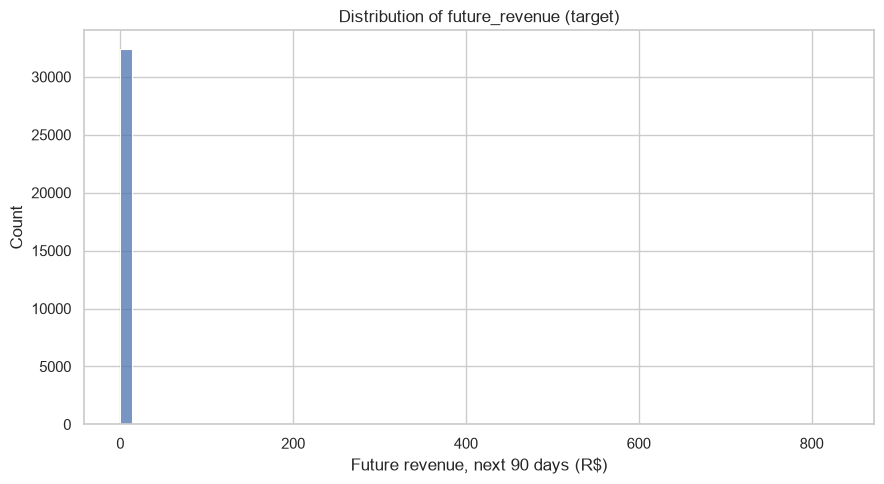

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(customer_feat['future_revenue'], bins=60, ax=ax)
ax.set_title('Distribution of future_revenue (target)')
ax.set_xlabel('Future revenue, next 90 days (R$)')
plt.tight_layout()
plt.show()

In [5]:
dataset = customer_feat[[
    'customer_unique_id', 'recency_days', 'frequency', 'monetary_value',
    'avg_order_value', 'avg_basket_size', 'customer_tenure_days', 'avg_review_rating',
    'preferred_payment_method', 'customer_state_grouped', 'future_revenue'
]].copy()

dataset.to_csv(PROC_DIR / 'clv_prediction_dataset.csv', index=False)
print('Saved clv_prediction_dataset.csv', dataset.shape)

Saved clv_prediction_dataset.csv (32441, 11)


## Train/test split

In [6]:
numeric_features = ['recency_days', 'frequency', 'monetary_value', 'avg_order_value',
                    'avg_basket_size', 'customer_tenure_days', 'avg_review_rating']
categorical_features = ['preferred_payment_method', 'customer_state_grouped']

X = dataset[numeric_features + categorical_features]
y = dataset['future_revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

Train: (25952, 9)  |  Test: (6489, 9)


## Regression models

Linear Regression, Random Forest, Gradient Boosting, XGBoost, LightGBM, and
CatBoost

In [7]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(random_state=RANDOM_STATE, n_estimators=300),
    'LightGBM': LGBMRegressor(random_state=RANDOM_STATE, n_estimators=300, verbose=-1),
    'CatBoost': CatBoostRegressor(random_state=RANDOM_STATE, iterations=300, verbose=0),
}

fitted_pipelines = {}
for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocessor), ('reg', model)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    print(f'{name:20s} trained')

Linear Regression    trained
Random Forest        trained
Gradient Boosting    trained
XGBoost              trained
LightGBM             trained
CatBoost             trained


## Evaluation — RMSE, MAE, MAPE, R²

In [8]:
results = []
for name, pipe in fitted_pipelines.items():
    y_pred = pipe.predict(X_test)
    y_pred_clipped = np.clip(y_pred, 0, None)  # revenue can't be negative

    rmse = np.sqrt(mean_squared_error(y_test, y_pred_clipped))
    mae = mean_absolute_error(y_test, y_pred_clipped)
    r2 = r2_score(y_test, y_pred_clipped)

    # Standard MAPE is unstable near y_test==0 (division by ~0), which is most
    # of this target. Restrict it to customers with nonzero actual future
    # revenue - that's the trustworthy number.
    nonzero_mask = (y_test != 0).values
    if nonzero_mask.sum() > 0:
        mape_nonzero = mean_absolute_percentage_error(
            y_test[nonzero_mask], y_pred_clipped[nonzero_mask]
        )
    else:
        mape_nonzero = np.nan

    results.append({
        'model': name, 'rmse': rmse, 'mae': mae,
        'mape_nonzero_only': mape_nonzero, 'r2': r2,
    })

results_df = pd.DataFrame(results).sort_values('rmse')
results_df

,model,rmse,mae,mape_nonzero_only,r2
0,Linear Regression,9.706446,0.714071,0.994061,0.000557
2,Gradient Boosting,10.023915,0.719568,0.991710,-0.065889
4,LightGBM,10.191112,1.086446,0.986125,-0.101744
1,Random Forest,12.384264,0.923829,0.993427,-0.626963
5,CatBoost,12.623224,0.933969,0.995086,-0.690355
3,XGBoost,19.835320,1.416907,0.994702,-3.173648


C:\Users\Pavithran\AppData\Local\Temp\ipykernel_24092\4004337540.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=order, x=metric, y='model', ax=ax, palette='viridis')
C:\Users\Pavithran\AppData\Local\Temp\ipykernel_24092\4004337540.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=order, x=metric, y='model', ax=ax, palette='viridis')
C:\Users\Pavithran\AppData\Local\Temp\ipykernel_24092\4004337540.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=order, x=metric, y='model', ax=ax, palette='viridis')
C:\Users\Pavithran\

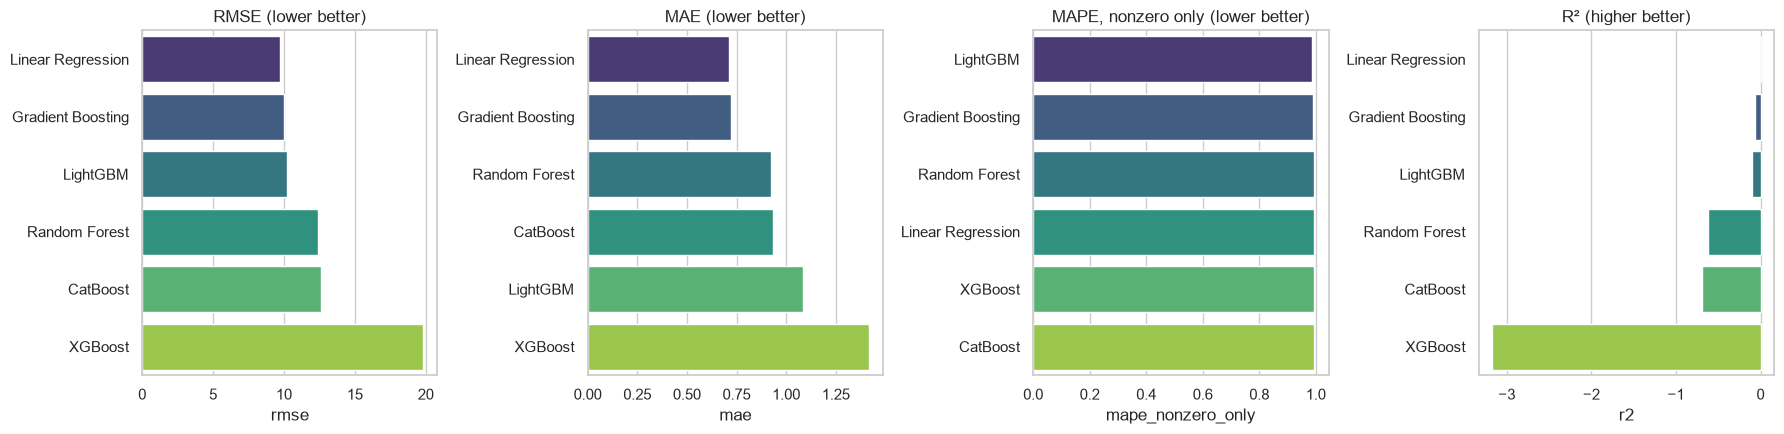

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
metrics_to_plot = ['rmse', 'mae', 'mape_nonzero_only', 'r2']
titles = ['RMSE (lower better)', 'MAE (lower better)', 'MAPE, nonzero only (lower better)', 'R² (higher better)']

for ax, metric, title in zip(axes, metrics_to_plot, titles):
    order = results_df.sort_values(metric, ascending=(metric != 'r2'))
    sns.barplot(data=order, x=metric, y='model', ax=ax, palette='viridis')
    ax.set_title(title)
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

## Best model & diagnostics

Best model by RMSE: Linear Regression
               model      rmse       mae  mape_nonzero_only        r2
0  Linear Regression  9.706446  0.714071           0.994061  0.000557


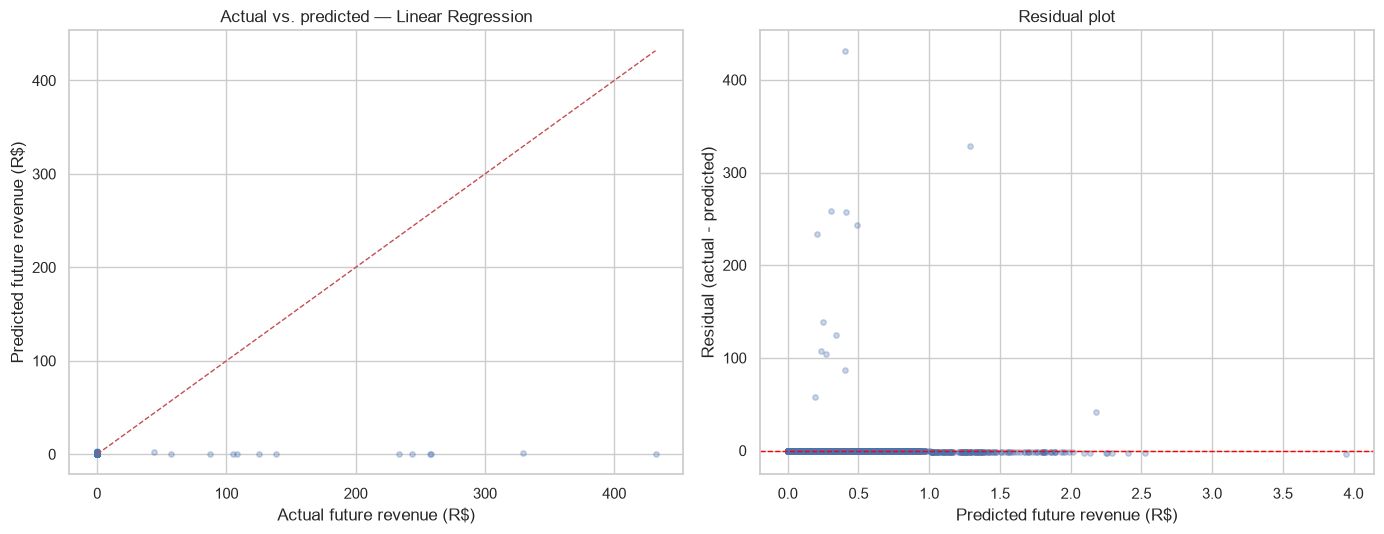

In [10]:
best_model_name = results_df.sort_values('rmse').iloc[0]['model']
best_pipeline = fitted_pipelines[best_model_name]
print(f'Best model by RMSE: {best_model_name}')
print(results_df[results_df['model'] == best_model_name])

y_pred_best = np.clip(best_pipeline.predict(X_test), 0, None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(y_test, y_pred_best, alpha=0.3, s=15)
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=1)
axes[0].set_xlabel('Actual future revenue (R$)')
axes[0].set_ylabel('Predicted future revenue (R$)')
axes[0].set_title(f'Actual vs. predicted — {best_model_name}')

residuals = y_test - y_pred_best
axes[1].scatter(y_pred_best, residuals, alpha=0.3, s=15)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_xlabel('Predicted future revenue (R$)')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residual plot')

plt.tight_layout()
plt.show()

In [11]:
joblib.dump(best_pipeline, MODELS_DIR / 'clv_prediction_model.pkl')
print(f"Saved best pipeline ({best_model_name}) to {MODELS_DIR / 'clv_prediction_model.pkl'}")

Saved best pipeline (Linear Regression) to ..\models\clv_prediction_model.pkl
